# 02 — UCI 697: análise exploratória

Predict Students' Dropout and Academic Success. **Nenhum modelo é treinado.**

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == "notebooks" else ROOT
sys.path.insert(0, str(ROOT))
import pandas as pd, numpy as np
from IPython.display import Image, display
pd.set_option("display.max_columns", 30, "display.width", 160)
FIG = ROOT / "research" / "figures"
from src.data.loaders import load_uci
from src.data.quality import uci_consistency
from src.analysis import eda, leakage, plots
df = load_uci(); df.shape

(4424, 37)

In [2]:
pd.DataFrame(uci_consistency(df)).T

,approved_gt_enrolled,grade_zero_with_approvals,grade_positive_without_approvals,enrolled_zero,enrolled_positive_zero_evaluations
1st,0,0,0,180,169
2nd,0,0,0,180,221
age_below_17,0,0,0,0,0
duplicate_rows,0,0,0,0,0
missing_cells,0,0,0,0,0


## 1. Classes

,count,proportion
Target,,
Graduate,2209,0.4993
Dropout,1421,0.3212
Enrolled,794,0.1795


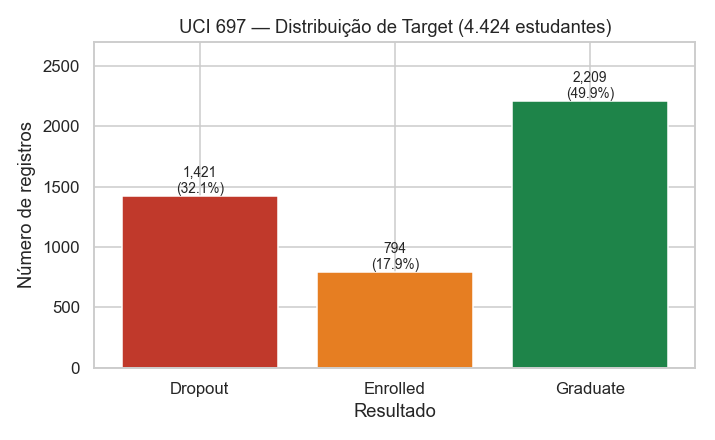

In [3]:
display(eda.distribution(df['Target'])); display(Image(FIG / 'uci_target_distribution.png'))

## 2. Variáveis de ingresso e desempenho por classe

In [4]:
df.groupby('Target')[['Admission grade', 'Age at enrollment', 'Curricular units 1st sem (approved)',
                      'Curricular units 1st sem (grade)', 'Curricular units 2nd sem (approved)']].median()

,Admission grade,Age at enrollment,Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 2nd sem (approved)
Target,,,,,
Dropout,123.6,23.0,2.0,10.928571,0.0
Enrolled,124.1,20.0,5.0,12.000000,4.0
Graduate,127.4,19.0,6.0,13.000000,6.0


In [5]:
df.groupby('Target')[['Debtor', 'Tuition fees up to date', 'Scholarship holder', 'Displaced', 'Gender']].mean().round(3)

,Debtor,Tuition fees up to date,Scholarship holder,Displaced,Gender
Target,,,,,
Dropout,0.220,0.678,0.094,0.471,0.493
Enrolled,0.113,0.947,0.164,0.545,0.387
Graduate,0.046,0.987,0.378,0.599,0.248


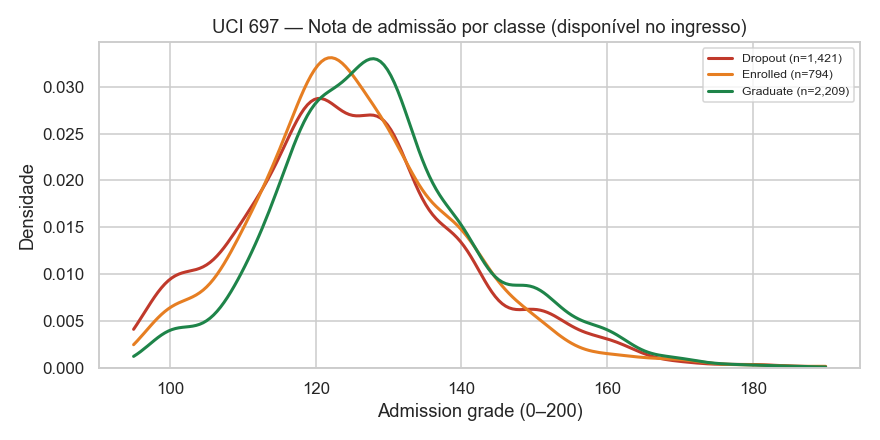

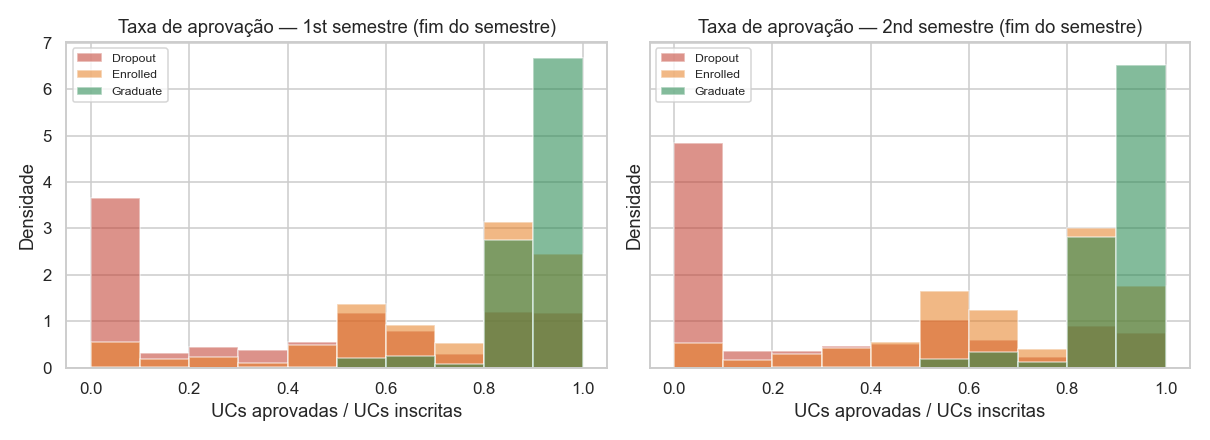

In [6]:
display(Image(FIG / 'uci_admission_grade_by_class.png')); display(Image(FIG / 'uci_semester_approval_by_class.png'))

## 3. O problema do rótulo `Enrolled`

`Enrolled` = ainda matriculado ao fim da duração normal: desfecho **censurado**. Seu perfil acadêmico fica entre Dropout e Graduate.

Target,Dropout,Enrolled,Graduate
row_0,,,
10.8|1.4|1.74,0.347,0.171,0.482
11.1|0.6|2.02,0.283,0.162,0.556
12.4|0.5|1.79,0.240,0.202,0.557
12.7|3.7|-1.7,0.337,0.150,0.513
13.9|-0.3|0.79,0.303,0.164,0.533
15.5|2.8|-4.06,0.350,0.174,0.476
16.2|0.3|-0.92,0.384,0.127,0.489
7.6|2.6|0.32,0.354,0.208,0.438
8.9|1.4|3.51,0.277,0.209,0.514


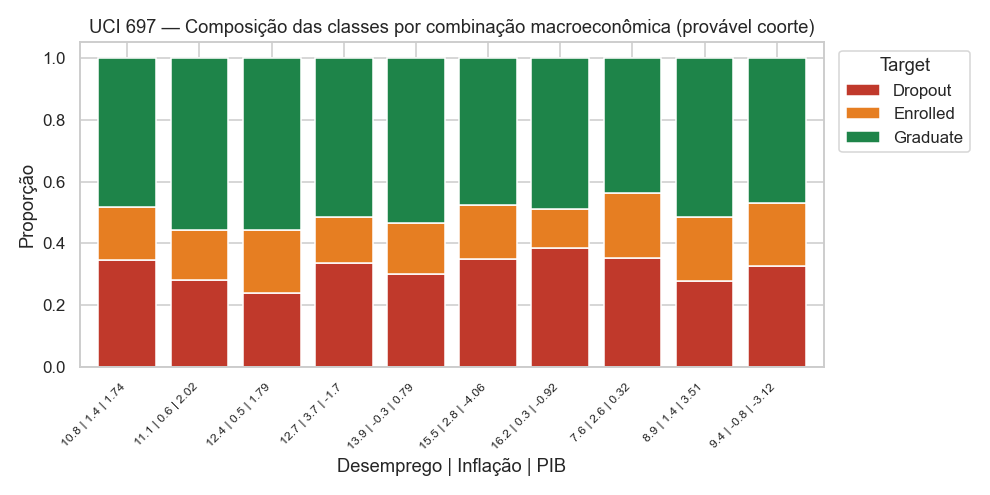

In [7]:
cohort = df['Unemployment rate'].astype(str) + '|' + df['Inflation rate'].astype(str) + '|' + df['GDP'].astype(str)
display(pd.crosstab(cohort, df['Target'], normalize='index').round(3))
display(Image(FIG / 'uci_cohort_proxy.png'))

## 4. Regras que revelam o desfecho

In [8]:
leakage.uci_outcome_revealing_rules(df)

,rule,n,share_dropout,share_enrolled,share_graduate
0,1st sem: enrolled>0 and evaluations==0,169,1.0000,0.0000,0.0000
1,1st sem: approved==0,718,0.7939,0.0989,0.1072
2,2nd sem: enrolled==0,180,0.4278,0.1556,0.4167
3,2nd sem: enrolled>0 and evaluations==0,221,0.9955,0.0045,0.0000
4,2nd sem: approved==0,870,0.8356,0.0782,0.0862
5,Tuition fees up to date == 0,528,0.8655,0.0795,0.0549
6,Debtor == 1,503,0.6203,0.1789,0.2008


## 5. Associações (descritivas)

In [9]:
sep = pd.read_csv(ROOT / 'research' / 'inspection' / 'uci_univariate_separation.csv')
sep[['variable', 'separation', 'cramers_v_3class', 'class', 'class_sem2']]

,variable,separation,cramers_v_3class,class,class_sem2
0,Curricular units 2nd sem (approved),0.7839,0.5453,PROHIBITED,PROHIBITED
1,Curricular units 1st sem (approved),0.7166,0.4816,PROHIBITED,PERMITTED
2,Curricular units 2nd sem (grade),0.6908,NaN,PROHIBITED,PROHIBITED
3,Curricular units 1st sem (grade),0.6176,NaN,PROHIBITED,PERMITTED
4,Age at enrollment,0.3680,0.2487,PERMITTED,PERMITTED
5,Tuition fees up to date,0.3085,0.4315,CONDITIONAL,CONDITIONAL
6,Scholarship holder,0.2837,0.3044,CONDITIONAL,CONDITIONAL
7,Curricular units 2nd sem (enrolled),0.2837,0.2189,PROHIBITED,CONDITIONAL
8,Curricular units 1st sem (enrolled),0.2718,0.2153,CONDITIONAL,PERMITTED
9,Gender,0.2452,0.2296,PERMITTED,PERMITTED


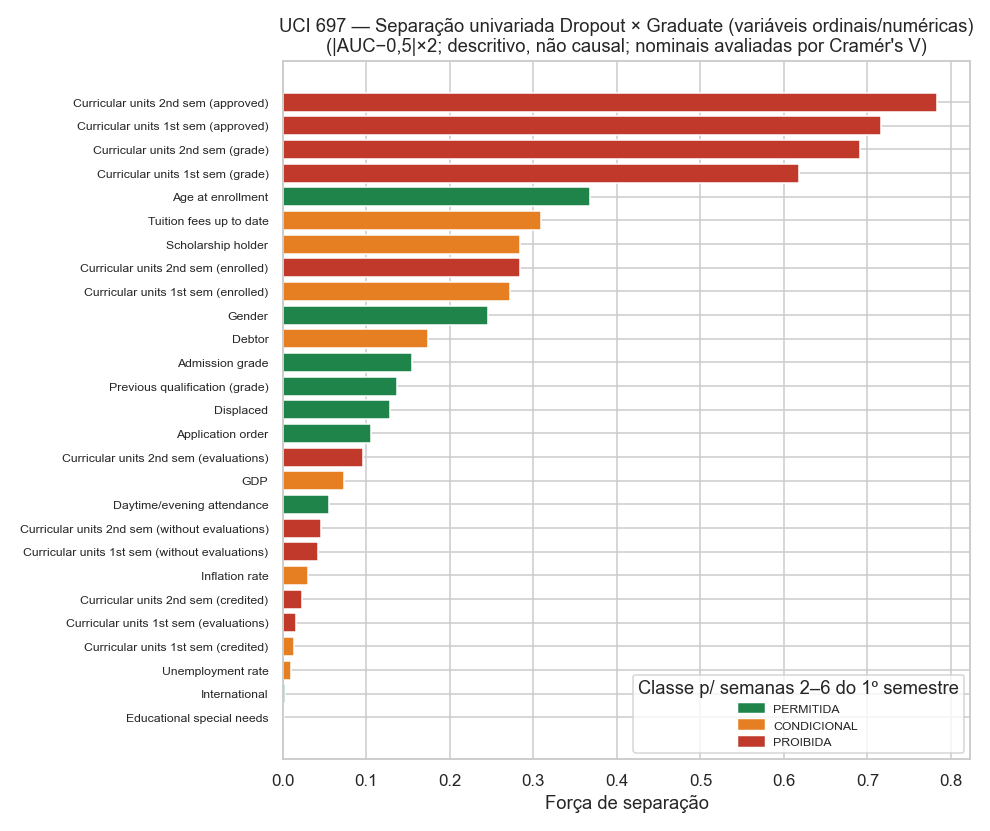

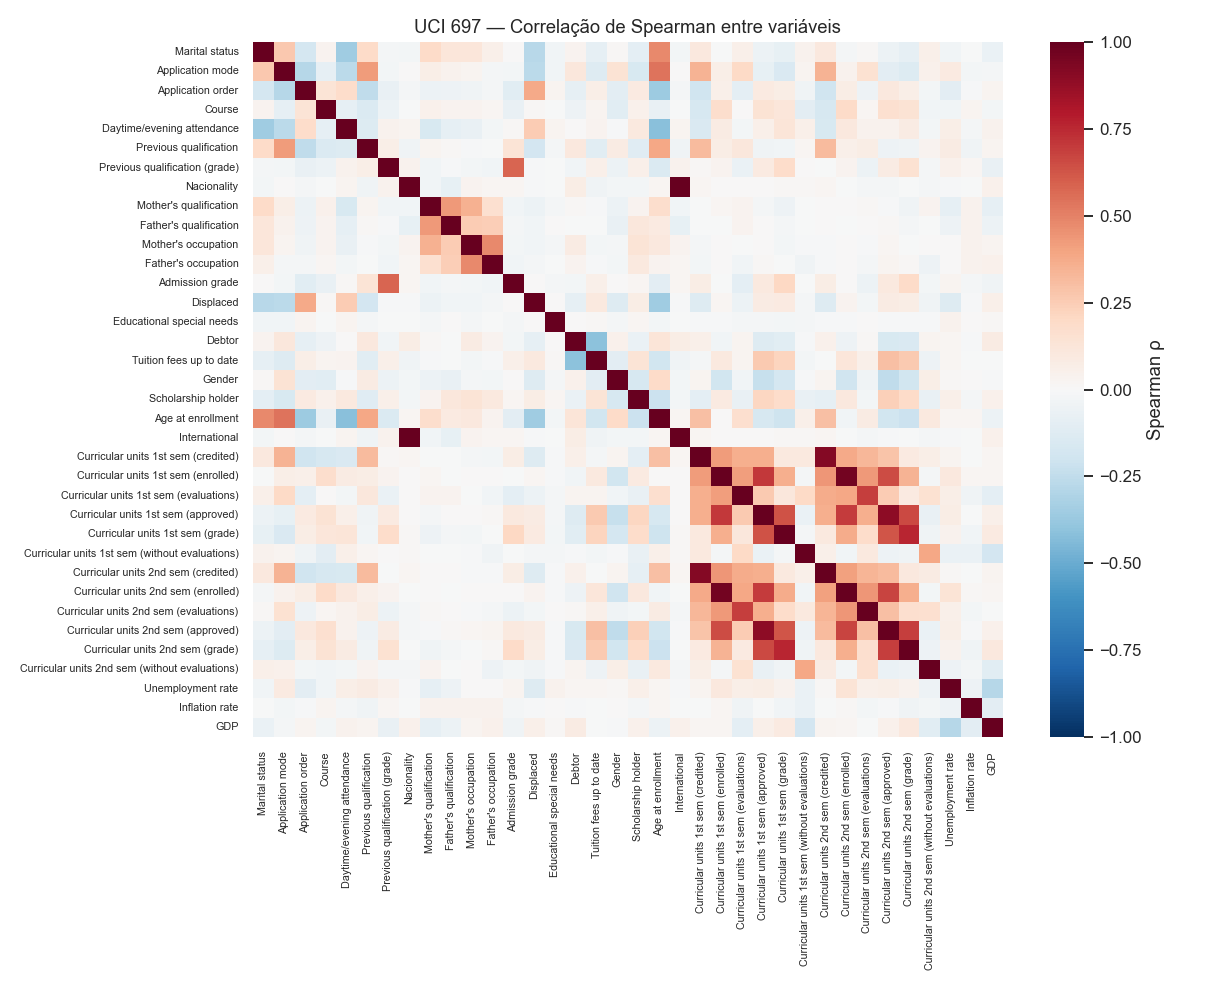

In [10]:
display(Image(FIG / 'uci_separation_by_availability.png')); display(Image(FIG / 'uci_spearman_correlation.png'))